In [15]:
from wpp import cache, data, db
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
with db.get_con() as con:
    pois_dim = cache.cached_parquet(
        "pois",
        lambda: data.load_pois(con),
    )
    poi_visits = cache.cached_parquet(
        "static_poi_segregation",
        lambda: data.load_static_poi_segregation(con),
    ).with_columns(pl.col("TOTAL_VISITORS").cast(pl.Float64))
    poi_visits_weekly = cache.cached_parquet(
        "weekly_poi_segregation",
        lambda: data.load_weekly_poi_segregation(con),
    )

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [12]:
pois_weekly = pois_dim.join(poi_visits_weekly, on="ID_STORE")
pois_weekly.head()

CBSA_NAME,ID_STORE,POI_GEOID,CBSAFP,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,NAICS_TITLE,CBSA_NAME_FULL,DATE_RANGE_START,DATE_RANGE_END,AVG_TMEAN,AVG_TMIN,AVG_TMAX,NUM_TEMPERATURE_DAYS,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,AVG_DIST_1,AVG_DIST_2,AVG_DIST_3,AVG_DIST_4,NUM_HOME_GROUPS_1,NUM_HOME_GROUPS_2,NUM_HOME_GROUPS_3,NUM_HOME_GROUPS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION,AVG_DIST,NUM_HOME_GROUPS
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i32,"decimal[38,0]",str,str,str,datetime[μs],datetime[μs],f64,f64,f64,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64,f64,i64
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,122651,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2025-01-06 00:00:00,2025-01-12 00:00:00,-1.284364,-3.909686,1.340957,7,1081,393,98,null,1009.971061,2546.986159,4022.610174,null,5,3,1,0,1572,0.687659,0.25,0.062341,null,0.416879,1582.035671,9
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,122651,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2025-01-13 00:00:00,2025-01-19 00:00:00,0.753164,-2.1068,3.613128,7,843,748,188,null,1522.030213,2730.453021,13756.913608,null,7,6,2,0,1779,0.473862,0.420461,0.105677,null,0.359097,3323.07481,15
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,122651,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2025-01-20 00:00:00,2025-01-26 00:00:00,-4.866614,-8.205857,-1.527371,7,536,402,null,null,767.473235,11456.045011,null,null,3,3,0,0,938,0.571429,0.428571,null,null,0.333333,5348.28971,6
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,122651,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2025-01-27 00:00:00,2025-02-02 00:00:00,2.490921,-1.540829,6.522671,7,523,315,null,null,2768.010514,3072.960822,null,null,3,3,0,0,838,0.624105,0.375895,null,null,0.333333,2882.639806,6
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,122651,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2025-02-03 00:00:0

In [28]:
pois_weekly["AVG_DIST"].describe()

statistic,value
str,f64
"""count""",1.0912858e7
"""null_count""",0.0
"""mean""",NaN
"""std""",NaN
"""min""",0.405531
"""25%""",2022.043526
"""50%""",4306.233316
"""75%""",8361.836036
"""max""",268306.117373


In [35]:
def plot(agg, axes):
    plots = [
        ("NUM_ROWS", "Rows"),
        ("NUM_POIS", "Unique POIs"),
        ("TOTAL_VISITORS", "Total visitors"),
        ("MEDIAN_VISITORS", "Median visitors per row"),
        ("MEAN_DIST", "Mean distance"),
        ("MEAN_SEGREGATION", "Mean segregation"),
    ]
    
    for ax, (column, title) in zip(axes.flat, plots):
        ax.plot(
            agg["DATE_RANGE_START"],
            agg[column],
        )
        ax.set_title(title)
        ax.grid(alpha=0.15)
    
    axes[2, 0].set_ylabel("Distance")
    axes[2, 1].set_ylabel("Segregation")
    
    sns.despine(fig=fig)

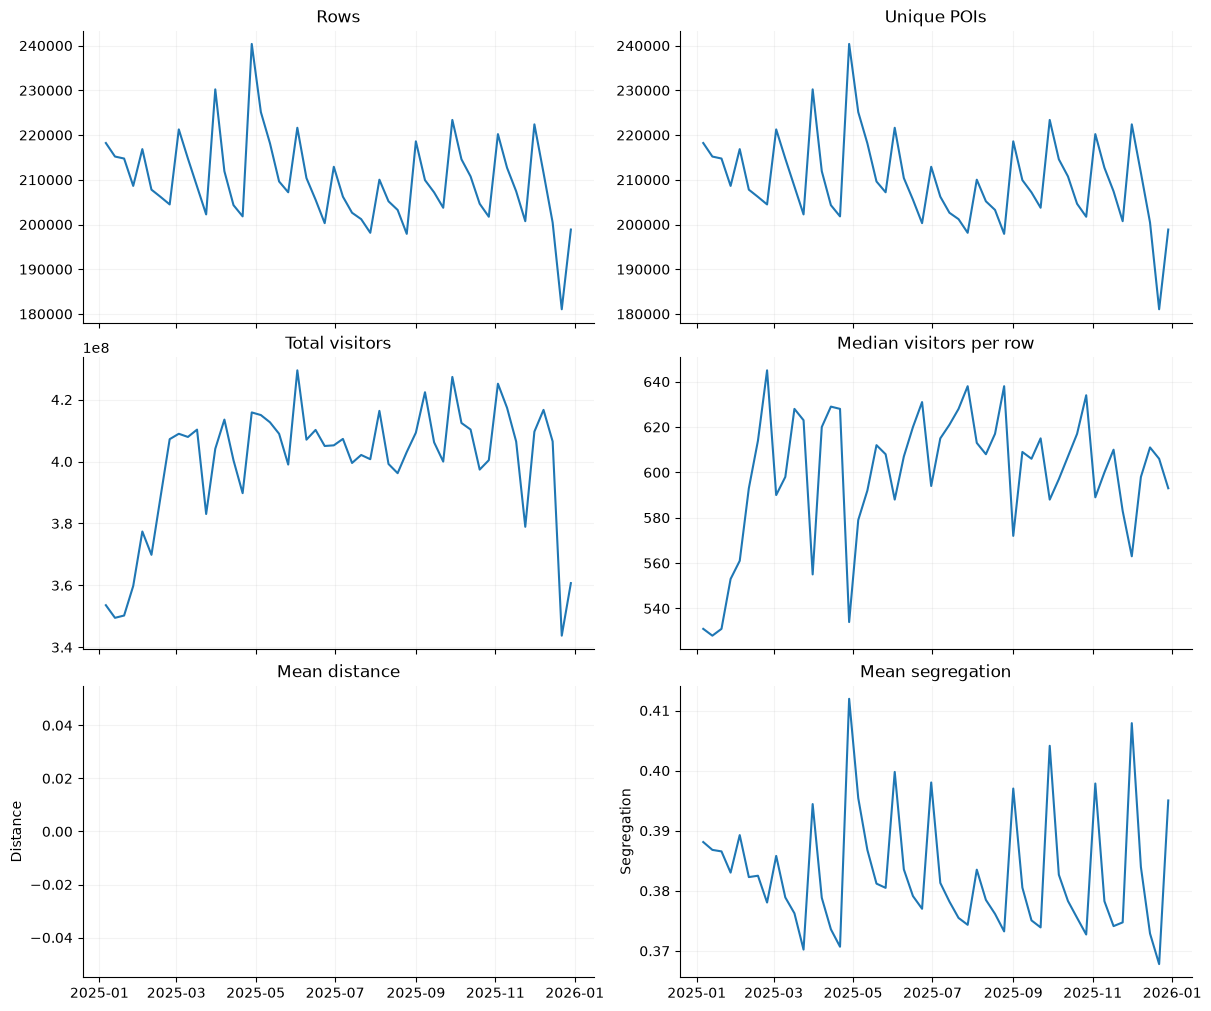

In [38]:
fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True,
)
agg = (
    pois_weekly.group_by("DATE_RANGE_START")
    .agg(
        pl.len().alias("NUM_ROWS"),
        pl.col("ID_STORE").n_unique().alias("NUM_POIS"),
        pl.col("TOTAL_VISITORS").sum().alias("TOTAL_VISITORS"),
        pl.col("TOTAL_VISITORS").median().alias("MEDIAN_VISITORS"),
        pl.col("AVG_DIST").mean().alias("MEAN_DIST"),
        pl.col("SEGREGATION").mean().alias("MEAN_SEGREGATION"),
    )
    .sort("DATE_RANGE_START")
)
plot(agg, axes)